In [28]:
import random
import itertools
import matplotlib.pyplot as plt

members = "Tanmay Modi - B24CS047\n Y. Bhavadish - B24CS052\n Waveson Harit - B24CS051\n Toshit Jain - B24CS048\n Devanshu Sabharwal - B24DS007\n"
print("Group members:\n", members)

Group members:
 Tanmay Modi - B24CS047
 Y. Bhavadish - B24CS052
 Waveson Harit - B24CS051
 Toshit Jain - B24CS048
 Devanshu Sabharwal - B24DS007



In [29]:
states = {
    'W': ['Hot', 'Mild', 'Cold'], # Weather
    'D': ['Weekday', 'Weekend'], # Day Type
    'O': ['High', 'Low'], # Occupancy
    'A': ['On', 'Off'], # AC usage
    'L': ['Heavy', 'Light'], # Appliance Load
    'E': ['High', 'Low'], # Energy Consumption
}
parents = {'W': [], 'D': [], 'O': ['D'], 'A': ['W', 'O'], 'L': ['O'], 'E': ['A', 'L']}
order = ['W', 'D', 'O', 'A', 'L', 'E']   # topological order

In [30]:
# cpt[var][parent values] = probabilities, in the same order as states[var]
expert = {
    'W': {(): [0.50, 0.30, 0.20]},
    'D': {(): [0.70, 0.30]},
    'O': {('Weekday',): [0.45, 0.55],
          ('Weekend',): [0.80, 0.20]},
    'A': {('Hot', 'High'): [0.90, 0.10],
          ('Hot', 'Low'): [0.60, 0.40],
          ('Mild', 'High'): [0.40, 0.60],
          ('Mild', 'Low'): [0.15, 0.85],
          ('Cold', 'High'): [0.10, 0.90],
          ('Cold', 'Low'): [0.05, 0.95]},
    'L': {('High',): [0.75, 0.25],
          ('Low',): [0.35, 0.65]},
    'E': {('On', 'Heavy'): [0.92, 0.08],
          ('On', 'Light'): [0.68, 0.32],
          ('Off', 'Heavy'): [0.55, 0.45],
          ('Off', 'Light'): [0.12, 0.88]},
}

In [31]:
# check_cpt
# Checks that a CPT is valid: every combination of parent values has a row,
# each row has one probability per child state, and each row sums to 1.
def check_cpt(cpt):
    for v in order:
        for cfg in itertools.product(*[states[p] for p in parents[v]]):
            assert cfg in cpt[v], f"missing row {v} | {cfg}"
            probs = cpt[v][cfg]
            assert len(probs) == len(states[v])
            assert abs(sum(probs) - 1) < 1e-9, f"{v} | {cfg} sums to {sum(probs)}"
    print("All CPTs are valid: every parent configuration is present and sums to 1")

check_cpt(expert)

All CPTs are valid: every parent configuration is present and sums to 1


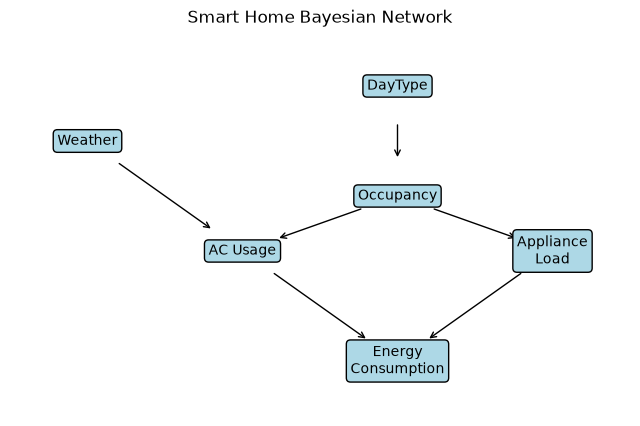

In [32]:
pos = {'W': (1, 2.5), 'D': (5, 3), 'O': (5, 2), 'A': (3, 1.5), 'L': (7, 1.5), 'E': (5, 0.5)}
full = {'W': 'Weather', 'D': 'DayType', 'O': 'Occupancy', 'A': 'AC Usage', 'L': 'Appliance\nLoad', 'E': 'Energy\nConsumption'}

plt.figure(figsize=(8, 5))
for child in order:
    for p in parents[child]:
        plt.annotate("", xy=pos[child], xytext=pos[p],
                     arrowprops=dict(arrowstyle="->", shrinkA=28, shrinkB=28))
for v in order:
    plt.text(*pos[v], full[v], ha='center', va='center',
             bbox=dict(boxstyle='round', fc='lightblue', ec='black'))
plt.xlim(0, 8)
plt.ylim(0, 3.5)
plt.axis('off')
plt.title("Smart Home Bayesian Network")
plt.show()

In [33]:
# joint
# Returns the probability of one full assignment (a value for every variable)
# by multiplying each variable's CPT entry given its parents' values.
def joint(cpt, a):
    p = 1.0
    for v in order:
        cfg = tuple(a[x] for x in parents[v])
        p *= cpt[v][cfg][states[v].index(a[v])]
    return p
# prob
# Returns the probability of a partial event (e.g. {'E': 'High', 'W': 'Hot'})
# by summing joint() over all full assignments consistent with the event.
def prob(cpt, event):
    total = 0.0
    for vals in itertools.product(*[states[v] for v in order]):
        a = dict(zip(order, vals))
        if all(a[k] == x for k, x in event.items()):
            total += joint(cpt, a)
    return total
# cond
# Returns P(target | evidence) as P(target, evidence) / P(evidence),
# computing both parts with prob().
def cond(cpt, target, evidence):
    return prob(cpt, {**target, **evidence}) / prob(cpt, evidence)

In [34]:
queries = {
    'Q1': ("P(E=High)",                          {'E': 'High'}, {}),
    'Q2': ("P(E=High | W=Hot)",                  {'E': 'High'}, {'W': 'Hot'}),
    'Q3': ("P(E=High | D=Weekend)",              {'E': 'High'}, {'D': 'Weekend'}),
    'Q4': ("P(E=High | W=Cold, O=High)",         {'E': 'High'}, {'W': 'Cold', 'O': 'High'}),
    'Q5': ("P(W=Hot | E=High)",                  {'W': 'Hot'},  {'E': 'High'}),
    'Q6': ("P(A=On | E=High)",                   {'A': 'On'},   {'E': 'High'}),
    'Q7': ("P(A=On | E=High, L=Heavy)",          {'A': 'On'},   {'E': 'High', 'L': 'Heavy'}),
}
# run_queries
# Runs Q1-Q7 on a given model (CPT set). Returns a dict.
def run_queries(cpt):
    return {q: cond(cpt, t, e) for q, (_, t, e) in queries.items()}

expert_res = run_queries(expert)
for q, (text, _, _) in queries.items():
    print(f"{q}: {text:<30} = {expert_res[q]:.4f}")

Q1: P(E=High)                      = 0.5806
Q2: P(E=High | W=Hot)              = 0.7063
Q3: P(E=High | D=Weekend)          = 0.6402
Q4: P(E=High | W=Cold, O=High)     = 0.4842
Q5: P(W=Hot | E=High)              = 0.6082
Q6: P(A=On | E=High)               = 0.6929
Q7: P(A=On | E=High, L=Heavy)      = 0.6499


In [35]:
print(f"Q6 = {expert_res['Q6']:.4f}, Q7 = {expert_res['Q7']:.4f}")
print(f"Change from Q6 to Q7: {expert_res['Q7'] - expert_res['Q6']:+.4f}")
print("""
Explaining away: A (AC) and L (Appliance Load) are both parents of E, so they are
independent causes of high energy. Observing E=High makes both causes more likely.
Once we also learn L=Heavy, that already accounts for much of the high consumption,
so there is less need to believe the AC was on. P(AC=On) drops from Q6 to Q7.
""")

Q6 = 0.6929, Q7 = 0.6499
Change from Q6 to Q7: -0.0430

Explaining away: A (AC) and L (Appliance Load) are both parents of E, so they are
independent causes of high energy. Observing E=High makes both causes more likely.
Once we also learn L=Heavy, that already accounts for much of the high consumption,
so there is less need to believe the AC was on. P(AC=On) drops from Q6 to Q7.



In [36]:
print("""
PART B: d-separation

1. Weather _|_ DayType  (holds)
   Paths from W to D: W -> A <- O <- D, and W -> A -> E <- L <- O <- D.
   On the first, A is a collider that is not observed (and neither is its descendant E), so it is blocked.
   On the second, E is an unobserved collider, so it is blocked too. Every path is blocked.

2. Weather _|_ DayType | EnergyConsumption  (does NOT hold)
   Observing E opens the colliders. On W -> A <- O <- D, A has the observed descendant E, so the
   collider A is active, and O and D are non-colliders that are not observed. This path is open.
   (W -> A -> E <- L <- O <- D is open as well, since E itself is observed.)

3. Weather _|_ ApplianceLoad | Occupancy  (holds)
   Paths from W to L: W -> A <- O -> L and W -> A -> E <- L.
   On the first, O is observed and is a non-collider (fork), so it blocks the path.
   On the second, E is an unobserved collider, so it blocks the path. Every path is blocked.
""")


PART B: d-separation

1. Weather _|_ DayType  (holds)
   Paths from W to D: W -> A <- O <- D, and W -> A -> E <- L <- O <- D.
   On the first, A is a collider that is not observed (and neither is its descendant E), so it is blocked.
   On the second, E is an unobserved collider, so it is blocked too. Every path is blocked.

2. Weather _|_ DayType | EnergyConsumption  (does NOT hold)
   Observing E opens the colliders. On W -> A <- O <- D, A has the observed descendant E, so the
   collider A is active, and O and D are non-colliders that are not observed. This path is open.
   (W -> A -> E <- L <- O <- D is open as well, since E itself is observed.)

3. Weather _|_ ApplianceLoad | Occupancy  (holds)
   Paths from W to L: W -> A <- O -> L and W -> A -> E <- L.
   On the first, O is observed and is a non-collider (fork), so it blocks the path.
   On the second, E is an unobserved collider, so it blocks the path. Every path is blocked.



In [37]:
# show
# Prints two probabilities and their difference side by side, used to check
# the d-separation results numerically.
def show(label, a, b):
    print(f"{label}")
    print(f"   {a[0]} = {a[1]:.6f}")
    print(f"   {b[0]} = {b[1]:.6f}")
    print(f"   difference = {abs(a[1] - b[1]):.6f}\n")

hot = {'W': 'Hot'}

show("1. W _|_ D",
     ("P(W=Hot)", cond(expert, hot, {})),
     ("P(W=Hot | D=Weekend)", cond(expert, hot, {'D': 'Weekend'})))

show("2. W _|_ D | E",
     ("P(W=Hot | E=High)", cond(expert, hot, {'E': 'High'})),
     ("P(W=Hot | E=High, D=Weekend)", cond(expert, hot, {'E': 'High', 'D': 'Weekend'})))

show("3. W _|_ L | O",
     ("P(W=Hot | O=High)", cond(expert, hot, {'O': 'High'})),
     ("P(W=Hot | O=High, L=Heavy)", cond(expert, hot, {'O': 'High', 'L': 'Heavy'})))

1. W _|_ D
   P(W=Hot) = 0.500000
   P(W=Hot | D=Weekend) = 0.500000
   difference = 0.000000

2. W _|_ D | E
   P(W=Hot | E=High) = 0.608188
   P(W=Hot | E=High, D=Weekend) = 0.599751
   difference = 0.008437

3. W _|_ L | O
   P(W=Hot | O=High) = 0.500000
   P(W=Hot | O=High, L=Heavy) = 0.500000
   difference = 0.000000



In [ ]:
# draw
# Samples one value from a discrete distribution: takes a uniform random number
# and returns the first value whose cumulative probability exceeds it.
def draw(probs, vals, rng):
    r = rng.random()
    cuml = 0.0
    for val, p in zip(vals, probs):
        cuml += p
        if r < cuml:
            return val
    return vals[-1]
# sample
# Ancestral sampling: generates one full row by visiting variables in
# topological order and drawing each from its CPT row for the already-sampled parents.
def sample(cpt, rng):
    a = {}
    for v in order:
        cfg = tuple(a[x] for x in parents[v])
        a[v] = draw(cpt[v][cfg], states[v], rng)
    return a

In [39]:
SEED = 42
sizes = [500, 5000, 20000]

rng = random.Random(SEED)
datasets = {n: [sample(expert, rng) for _ in range(n)] for n in sizes}
print("Random seed:", SEED)

Random seed: 42


In [40]:
for n, data in datasets.items():
    print(f"--- n = {n} ---")
    print("Weather frequencies:")
    for w in states['W']:
        c = sum(1 for row in data if row['W'] == w)
        print(f"   {w:<5} {c:>6}  {c / n:.4f}   (expert {expert['W'][()][states['W'].index(w)]})")
    print("(Weather, Occupancy) counts:")
    for w in states['W']:
        for o in states['O']:
            c = sum(1 for row in data if row['W'] == w and row['O'] == o)
            print(f"   ({w}, {o}) : {c}")
    print()

--- n = 500 ---
Weather frequencies:
   Hot      250  0.5000   (expert 0.5)
   Mild     139  0.2780   (expert 0.3)
   Cold     111  0.2220   (expert 0.2)
(Weather, Occupancy) counts:
   (Hot, High) : 144
   (Hot, Low) : 106
   (Mild, High) : 78
   (Mild, Low) : 61
   (Cold, High) : 56
   (Cold, Low) : 55

--- n = 5000 ---
Weather frequencies:
   Hot     2504  0.5008   (expert 0.5)
   Mild    1454  0.2908   (expert 0.3)
   Cold    1042  0.2084   (expert 0.2)
(Weather, Occupancy) counts:
   (Hot, High) : 1409
   (Hot, Low) : 1095
   (Mild, High) : 828
   (Mild, Low) : 626
   (Cold, High) : 560
   (Cold, Low) : 482

--- n = 20000 ---
Weather frequencies:
   Hot    10053  0.5027   (expert 0.5)
   Mild    5979  0.2989   (expert 0.3)
   Cold    3968  0.1984   (expert 0.2)
(Weather, Occupancy) counts:
   (Hot, High) : 5605
   (Hot, Low) : 4448
   (Mild, High) : 3378
   (Mild, Low) : 2601
   (Cold, High) : 2202
   (Cold, Low) : 1766



In [41]:
# count_data
# Counts how often each child value occurs for each parent configuration,
# for every variable. These counts are the input to both estimators.
def count_data(data):
    counts = {}
    for v in order:
        counts[v] = {}
        for cfg in itertools.product(*[states[p] for p in parents[v]]):
            counts[v][cfg] = [0] * len(states[v])
    for row in data:
        for v in order:
            cfg = tuple(row[p] for p in parents[v])
            counts[v][cfg][states[v].index(row[v])] += 1
    return counts

In [42]:
# learn_mle
# Maximum likelihood CPTs: count / total for each parent configuration.
# Falls back to uniform if a configuration never appears in the data.
def learn_mle(counts):
    cpt = {}
    for v in order:
        cpt[v] = {}
        for cfg, c in counts[v].items():
            total = sum(c)
            cpt[v][cfg] = [x / total for x in c] if total > 0 else [1 / len(c)] * len(c)
    return cpt

In [43]:
# BDeu: pseudo-count for each (parent config, child value) = ess / (num parent configs * num child values)

# learn_bdeu
# Bayesian CPTs with a BDeu prior: adds a pseudo-count of ess / (q * r)
# to every cell (q = number of parent configs, r = number of child states),
# then normalises, which pulls estimates towards uniform.
def learn_bdeu(counts, ess=10):
    cpt = {}
    for v in order:
        cpt[v] = {}
        q = len(counts[v])
        r = len(states[v])
        a = ess / (q * r)
        for cfg, c in counts[v].items():
            total = sum(c) + r * a
            cpt[v][cfg] = [(x + a) / total for x in c]
    return cpt

In [44]:
mle, bdeu = {}, {}
for n, data in datasets.items():
    counts = count_data(data)
    mle[n] = learn_mle(counts)
    bdeu[n] = learn_bdeu(counts, ess=10)
    check_cpt(mle[n])
    check_cpt(bdeu[n])

All CPTs are valid: every parent configuration is present and sums to 1
All CPTs are valid: every parent configuration is present and sums to 1
All CPTs are valid: every parent configuration is present and sums to 1
All CPTs are valid: every parent configuration is present and sums to 1
All CPTs are valid: every parent configuration is present and sums to 1
All CPTs are valid: every parent configuration is present and sums to 1


In [45]:
for n in sizes:
    print(f"--- P(AC=On | Weather, Occupancy), n = {n} ---")
    print(f"{'Weather':<8}{'Occ':<6}{'Expert':>9}{'MLE':>9}{'BDeu':>9}")
    for cfg in expert['A']:
        print(f"{cfg[0]:<8}{cfg[1]:<6}{expert['A'][cfg][0]:>9.4f}{mle[n]['A'][cfg][0]:>9.4f}{bdeu[n]['A'][cfg][0]:>9.4f}")
    print()

--- P(AC=On | Weather, Occupancy), n = 500 ---
Weather Occ      Expert      MLE     BDeu
Hot     High     0.9000   0.8819   0.8776
Hot     Low      0.6000   0.6226   0.6207
Mild    High     0.4000   0.4487   0.4498
Mild    Low      0.1500   0.1803   0.1888
Cold    High     0.1000   0.0536   0.0665
Cold    Low      0.0500   0.0182   0.0324

--- P(AC=On | Weather, Occupancy), n = 5000 ---
Weather Occ      Expert      MLE     BDeu
Hot     High     0.9000   0.8992   0.8987
Hot     Low      0.6000   0.6119   0.6117
Mild    High     0.4000   0.3889   0.3891
Mild    Low      0.1500   0.1502   0.1511
Cold    High     0.1000   0.0982   0.0994
Cold    Low      0.0500   0.0622   0.0637

--- P(AC=On | Weather, Occupancy), n = 20000 ---
Weather Occ      Expert      MLE     BDeu
Hot     High     0.9000   0.8942   0.8941
Hot     Low      0.6000   0.5964   0.5964
Mild    High     0.4000   0.3988   0.3988
Mild    Low      0.1500   0.1503   0.1506
Cold    High     0.1000   0.1081   0.1084
Cold    Low   

In [46]:
mle_res = {n: run_queries(mle[n]) for n in sizes}
bdeu_res = {n: run_queries(bdeu[n]) for n in sizes}

for n in sizes:
    print(f"--- Queries Q1-Q7, n = {n} ---")
    for q in queries:
        print(f"{q}: expert {expert_res[q]:.4f} | MLE {mle_res[n][q]:.4f} | BDeu {bdeu_res[n][q]:.4f}")
    print()

--- Queries Q1-Q7, n = 500 ---
Q1: expert 0.5806 | MLE 0.5905 | BDeu 0.5888
Q2: expert 0.7063 | MLE 0.7003 | BDeu 0.6951
Q3: expert 0.6402 | MLE 0.6493 | BDeu 0.6434
Q4: expert 0.4842 | MLE 0.5073 | BDeu 0.5100
Q5: expert 0.6082 | MLE 0.5929 | BDeu 0.5863
Q6: expert 0.6929 | MLE 0.6619 | BDeu 0.6589
Q7: expert 0.6499 | MLE 0.6326 | BDeu 0.6305

--- Queries Q1-Q7, n = 5000 ---
Q1: expert 0.5806 | MLE 0.5852 | BDeu 0.5851
Q2: expert 0.7063 | MLE 0.7188 | BDeu 0.7182
Q3: expert 0.6402 | MLE 0.6447 | BDeu 0.6440
Q4: expert 0.4842 | MLE 0.4806 | BDeu 0.4810
Q5: expert 0.6082 | MLE 0.6151 | BDeu 0.6143
Q6: expert 0.6929 | MLE 0.7003 | BDeu 0.6999
Q7: expert 0.6499 | MLE 0.6536 | BDeu 0.6534

--- Queries Q1-Q7, n = 20000 ---
Q1: expert 0.5806 | MLE 0.5819 | BDeu 0.5818
Q2: expert 0.7063 | MLE 0.7058 | BDeu 0.7056
Q3: expert 0.6402 | MLE 0.6407 | BDeu 0.6405
Q4: expert 0.4842 | MLE 0.4854 | BDeu 0.4855
Q5: expert 0.6082 | MLE 0.6097 | BDeu 0.6095
Q6: expert 0.6929 | MLE 0.6930 | BDeu 0.6929
Q7

In [47]:
mean_mle, mean_bdeu = {}, {}
for n in sizes:
    print(f"--- Comparison, n = {n} ---")
    print(f"{'Query':<7}{'Expert':>9}{'MLE':>9}{'Bayesian':>10}{'|Diff| MLE':>13}{'|Diff| Bayes':>14}")
    d_mle, d_bdeu = [], []
    for q in queries:
        e, m, b = expert_res[q], mle_res[n][q], bdeu_res[n][q]
        d_mle.append(abs(e - m))
        d_bdeu.append(abs(e - b))
        print(f"{q:<7}{e:>9.4f}{m:>9.4f}{b:>10.4f}{d_mle[-1]:>13.4f}{d_bdeu[-1]:>14.4f}")
    mean_mle[n] = sum(d_mle) / len(d_mle)
    mean_bdeu[n] = sum(d_bdeu) / len(d_bdeu)
    print(f"{'Mean':<7}{'':>9}{'':>9}{'':>10}{mean_mle[n]:>13.4f}{mean_bdeu[n]:>14.4f}\n")

--- Comparison, n = 500 ---
Query     Expert      MLE  Bayesian   |Diff| MLE  |Diff| Bayes
Q1        0.5806   0.5905    0.5888       0.0099        0.0082
Q2        0.7063   0.7003    0.6951       0.0060        0.0112
Q3        0.6402   0.6493    0.6434       0.0091        0.0032
Q4        0.4842   0.5073    0.5100       0.0230        0.0257
Q5        0.6082   0.5929    0.5863       0.0153        0.0218
Q6        0.6929   0.6619    0.6589       0.0310        0.0340
Q7        0.6499   0.6326    0.6305       0.0173        0.0194
Mean                                      0.0159        0.0176

--- Comparison, n = 5000 ---
Query     Expert      MLE  Bayesian   |Diff| MLE  |Diff| Bayes
Q1        0.5806   0.5852    0.5851       0.0046        0.0045
Q2        0.7063   0.7188    0.7182       0.0126        0.0120
Q3        0.6402   0.6447    0.6440       0.0045        0.0038
Q4        0.4842   0.4806    0.4810       0.0037        0.0033
Q5        0.6082   0.6151    0.6143       0.0069        0.00

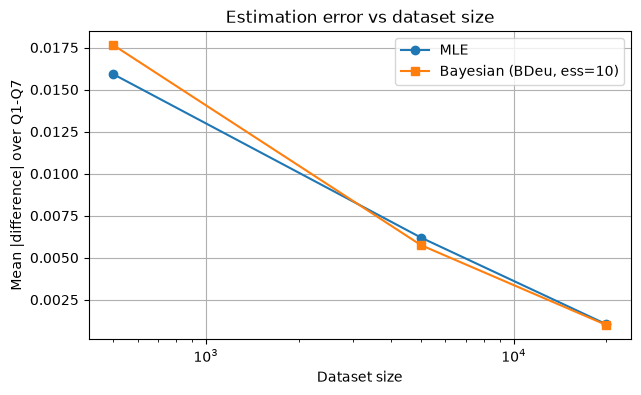

In [48]:
plt.figure(figsize=(7, 4))
plt.plot(sizes, [mean_mle[n] for n in sizes], marker='o', label='MLE')
plt.plot(sizes, [mean_bdeu[n] for n in sizes], marker='s', label='Bayesian (BDeu, ess=10)')
plt.xscale('log')
plt.xlabel('Dataset size')
plt.ylabel('Mean |difference| over Q1-Q7')
plt.title('Estimation error vs dataset size')
plt.legend()
plt.grid(True)
plt.show()

In [49]:
# evidence_count
# Counts how many rows in a dataset match the given evidence, used to show
# that rare evidence (like Cold + High occupancy) leaves little data to learn from.
def evidence_count(data, evidence):
    return sum(1 for row in data if all(row[k] == v for k, v in evidence.items()))

n = 500
print(f"n = {n}: evidence frequency and error per query")
print(f"{'Query':<7}{'Evidence':<22}{'Matches':>9}{'Err MLE':>10}{'Err Bayes':>11}")
for q, (_, _, ev) in queries.items():
    ev_text = ", ".join(f"{k}={v}" for k, v in ev.items()) or "none"
    cnt = evidence_count(datasets[n], ev)
    print(f"{q:<7}{ev_text:<22}{cnt:>9}{abs(expert_res[q] - mle_res[n][q]):>10.4f}{abs(expert_res[q] - bdeu_res[n][q]):>11.4f}")

worst_mle = max(queries, key=lambda q: abs(expert_res[q] - mle_res[n][q]))
worst_bdeu = max(queries, key=lambda q: abs(expert_res[q] - bdeu_res[n][q]))
print(f"\nLargest error at n={n}: MLE -> {worst_mle}, Bayesian -> {worst_bdeu}")

n = 500: evidence frequency and error per query
Query  Evidence                Matches   Err MLE  Err Bayes
Q1     none                        500    0.0099     0.0082
Q2     W=Hot                       250    0.0060     0.0112
Q3     D=Weekend                   146    0.0091     0.0032
Q4     W=Cold, O=High               56    0.0230     0.0257
Q5     E=High                      296    0.0153     0.0218
Q6     E=High                      296    0.0310     0.0340
Q7     E=High, L=Heavy             216    0.0173     0.0194

Largest error at n=500: MLE -> Q6, Bayesian -> Q6


In [50]:
# repeating at n=500 with many random seeds and taking the average to get close to expected answers
trials = 100
avg_mle = {q: 0.0 for q in queries}
avg_bdeu = {q: 0.0 for q in queries}
for s in range(trials):
    r = random.Random(1000 + s)
    d = [sample(expert, r) for _ in range(500)]
    c = count_data(d)
    rm, rb = run_queries(learn_mle(c)), run_queries(learn_bdeu(c))
    for q in queries:
        avg_mle[q] += abs(rm[q] - expert_res[q]) / trials
        avg_bdeu[q] += abs(rb[q] - expert_res[q]) / trials

print(f"Mean |diff| at n=500 over {trials} seeds")
print(f"{'Query':<7}{'MLE':>9}{'Bayes':>9}")
for q in queries:
    print(f"{q:<7}{avg_mle[q]:>9.4f}{avg_bdeu[q]:>9.4f}")
print(f"{'Mean':<7}{sum(avg_mle.values()) / 7:>9.4f}{sum(avg_bdeu.values()) / 7:>9.4f}")

Mean |diff| at n=500 over 100 seeds
Query        MLE    Bayes
Q1        0.0179   0.0176
Q2        0.0175   0.0183
Q3        0.0191   0.0194
Q4        0.0269   0.0264
Q5        0.0189   0.0182
Q6        0.0210   0.0210
Q7        0.0225   0.0226
Mean      0.0205   0.0205


In [51]:
worst_avg = max(queries, key=lambda q: avg_mle[q])
m_mle = sum(avg_mle.values()) / 7
m_bdeu = sum(avg_bdeu.values()) / 7
text = f"""
Largest error at n=500:
In the seed-42 dataset the largest error is {worst_mle} (MLE) / {worst_bdeu} (Bayesian), but a single draw is noisy.
Averaged over {trials} seeds the largest error is {worst_avg}: {queries[worst_avg][0]}.
Its evidence (W=Cold, O=High) has probability 0.2 * 0.555 = 0.111, so only about 55 of 500 samples
contain it (56 here). The probabilities it depends on, such as P(A | Cold, High), are estimated from
those few rows, so they have high variance. Queries with common evidence (no evidence, W=Hot, E=High)
are estimated from hundreds of rows and are more stable.

Estimator comparison:
All error comes from parameter estimates, since the structure is fixed. MLE uses raw frequencies,
which are unbiased but noisy when a parent configuration has few rows, and give 0 or 1 if a value is
never seen. BDeu adds ess/(q*r) pseudo-counts, shrinking each estimate towards uniform. This lowers
variance and never gives zero probabilities, at the cost of a small bias. Here every parent
configuration is seen ~50+ times even at n=500, so the prior has little effect: averaged errors are
{m_mle:.4f} (MLE) and {m_bdeu:.4f} (BDeu). BDeu helps more when data is sparser (rarer parent
configurations). At 20000 samples the pseudo-counts are negligible and both estimators agree.
"""
print(text)


Largest error at n=500:
In the seed-42 dataset the largest error is Q6 (MLE) / Q6 (Bayesian), but a single draw is noisy.
Averaged over 100 seeds the largest error is Q4: P(E=High | W=Cold, O=High).
Its evidence (W=Cold, O=High) has probability 0.2 * 0.555 = 0.111, so only about 55 of 500 samples
contain it (56 here). The probabilities it depends on, such as P(A | Cold, High), are estimated from
those few rows, so they have high variance. Queries with common evidence (no evidence, W=Hot, E=High)
are estimated from hundreds of rows and are more stable.

Estimator comparison:
All error comes from parameter estimates, since the structure is fixed. MLE uses raw frequencies,
which are unbiased but noisy when a parent configuration has few rows, and give 0 or 1 if a value is
never seen. BDeu adds ess/(q*r) pseudo-counts, shrinking each estimate towards uniform. This lowers
variance and never gives zero probabilities, at the cost of a small bias. Here every parent
configuration is seen ~50+ 